In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [3]:
df=pd.read_csv("creditcard.csv")
df.head(4)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0


In [4]:
print("Shape:",df.shape)


Shape: (284807, 31)


In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [10]:
print("Missing Values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

Missing Values:
Time      0
V16       0
Amount    0
V28       0
V27       0
V26       0
V25       0
V24       0
V23       0
V22       0
dtype: int64


In [11]:
print("Duplicate rows:",df.duplicated().sum())

Duplicate rows: 1081


In [12]:
print("Target distribution:")
print(df["Class"].value_counts())

print("\n Perncentage:")
print(df["Class"].value_counts(normalize=True)*100)

Target distribution:
Class
0    284315
1       492
Name: count, dtype: int64

 Perncentage:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


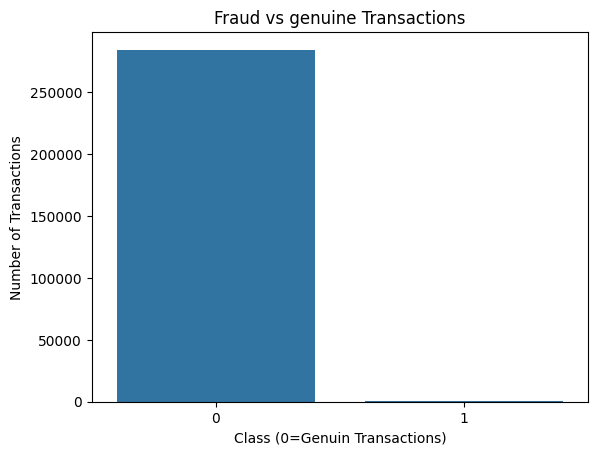

In [13]:
plt.Figure(figsize=(6,4))
sns.countplot(data=df,x="Class")

plt.title("Fraud vs genuine Transactions")
plt.xlabel("Class (0=Genuin Transactions)")
plt.ylabel("Number of Transactions")
plt.show()

In [14]:
fraud=df[df["Class"]==1]
genuine=df[df["Class"]==0]

print("Fraud transactions:",len(fraud))
print("Genuine transactions:",len(genuine))


Fraud transactions: 492
Genuine transactions: 284315


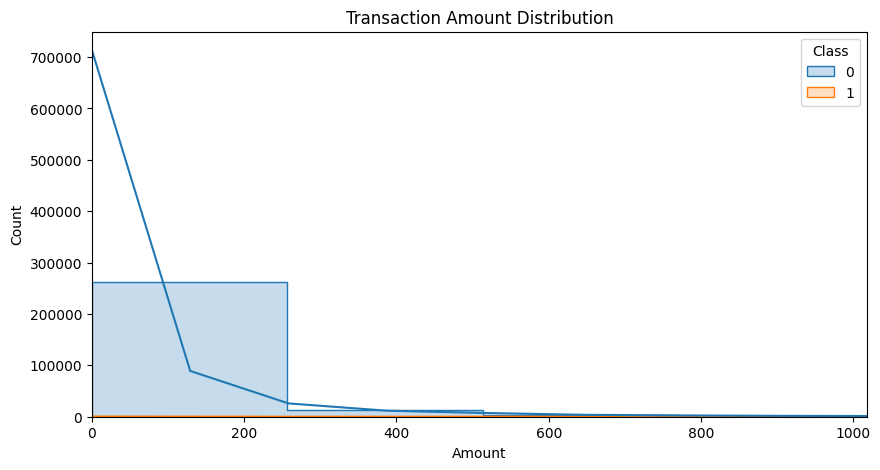

In [15]:
plt.figure(figsize=(10,5))
sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=100,
    kde=True,
    element="step"
)
plt.xlim(0,df["Amount"].quantile(0.99))
plt.title("Transaction Amount Distribution")
plt.show()

In [16]:
df.groupby("Class")["Amount"].describe() 

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


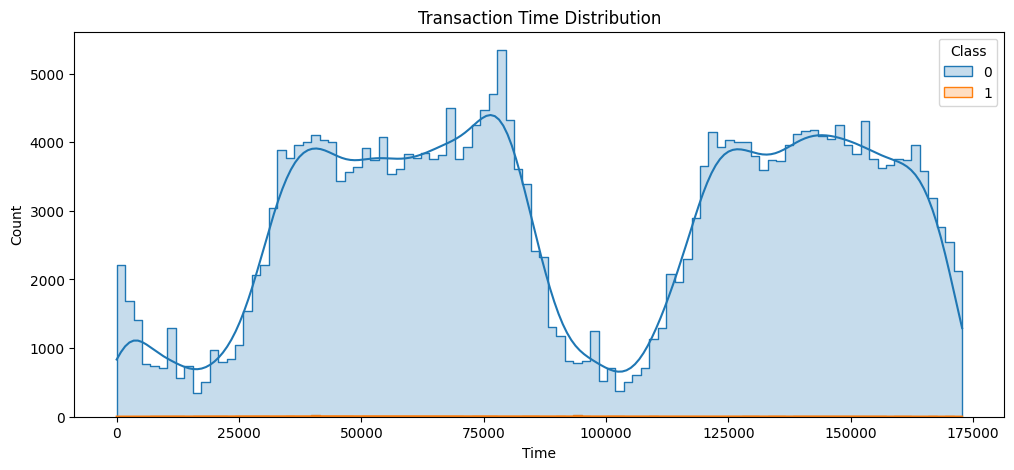

In [17]:
plt.figure(figsize=(12,5))
sns.histplot(    
    data=df,
    x="Time",
    hue="Class",
    bins=100,
    kde=True,
    element="step"
)
plt.title("Transaction Time Distribution")
plt.show()

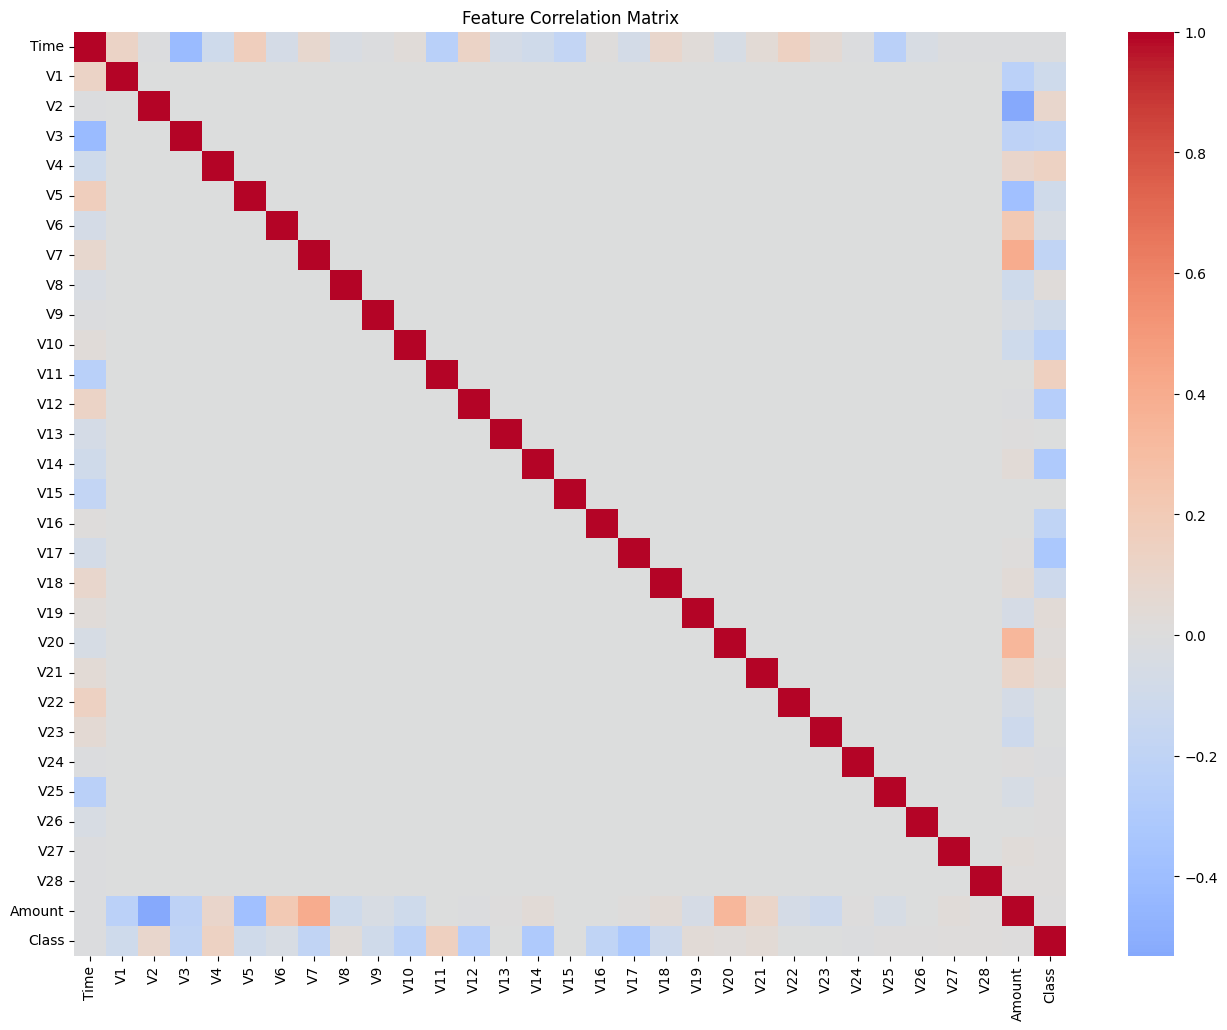

In [18]:
corr=df.corr(numeric_only=True)
plt.figure(figsize=(16,12))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0
)
plt.title("Feature Correlation Matrix")
plt.show()

In [19]:
fraud_corr=(
    df.corr(numeric_only=True)["Class"].drop("Class").sort_values()
)
fraud_corr

V17      -0.326481
V14      -0.302544
V12      -0.260593
V10      -0.216883
V16      -0.196539
V3       -0.192961
V7       -0.187257
V18      -0.111485
V1       -0.101347
V9       -0.097733
V5       -0.094974
V6       -0.043643
Time     -0.012323
V24      -0.007221
V13      -0.004570
V15      -0.004223
V23      -0.002685
V22       0.000805
V25       0.003308
V26       0.004455
Amount    0.005632
V28       0.009536
V27       0.017580
V8        0.019875
V20       0.020090
V19       0.034783
V21       0.040413
V2        0.091289
V4        0.133447
V11       0.154876
Name: Class, dtype: float64

In [20]:
print("Most negatively correlated:")
print(fraud_corr.head(10))

print("\n Most positively correlated:")
print(fraud_corr.tail(10))

Most negatively correlated:
V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V3    -0.192961
V7    -0.187257
V18   -0.111485
V1    -0.101347
V9    -0.097733
Name: Class, dtype: float64

 Most positively correlated:
Amount    0.005632
V28       0.009536
V27       0.017580
V8        0.019875
V20       0.020090
V19       0.034783
V21       0.040413
V2        0.091289
V4        0.133447
V11       0.154876
Name: Class, dtype: float64


In [21]:
df=df.drop_duplicates().reset_index(drop=True)
print("New Shape:",df.shape)

New Shape: (283726, 31)


In [22]:
df['Hour']=(df['Time']/3600)%24

In [23]:
df["Hour_sin"]=np.sin(2*np.pi*df['Hour']/24)
df["Hour_cos"]=np.cos(2*np.pi*df["Hour"]/24)

In [24]:
df=df.drop(columns=["Time","Hour"])

In [25]:
from sklearn.model_selection import train_test_split
X=df.drop(columns=["Class"])
y=df["Class"]

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,stratify=y,random_state=42)

In [26]:
print("Train:",X_train.shape)
print("Test:",X_test.shape)

print("\nTrain fraud ratio:")
print(y_train.mean())

print("\nTest fraud ratio:")
print(y_test.mean())


Train: (226980, 31)
Test: (56746, 31)

Train fraud ratio:
0.0016653449643140364

Test fraud ratio:
0.0016741268107003137


In [27]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report,confusion_matrix,roc_auc_score

fraud_ratio=y_train.mean()
scale_pos_weight=(1-fraud_ratio)/fraud_ratio

print("Scale_pos_weight:",scale_pos_weight)

Scale_pos_weight: 599.4761904761905


In [28]:
model=XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.85,
    colsample_btyree=0.85,
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weigth=scale_pos_weight,
    random_state=42,
    n_jobs=-1
)

In [29]:
model.fit(X_train,y_train,eval_set=[(X_test,y_test)],
verbose=False
)

c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\xgboost\core.py:158: UserWarning: [06:55:29] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0c55ff5f71b100e98-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "colsample_btyree", "scale_pos_weigth" } are not used.

  warnings.warn(smsg, UserWarning)


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'aucpr'


In [30]:
y_prob=model.predict_proba(X_test)[:,1]
y_pred=(y_prob>=0.5).astype(int)

In [31]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.99      0.74      0.84        95

    accuracy                           1.00     56746
   macro avg       0.99      0.87      0.92     56746
weighted avg       1.00      1.00      1.00     56746



In [32]:
from sklearn.metrics import average_precision_score

In [33]:
roc_auc=roc_auc_score(y_test,y_prob)
pr_auc=average_precision_score(y_test,y_prob)

print("ROC-AUC",roc_auc)
print("PR-AUC",pr_auc)

ROC-AUC 0.9753725720454602
PR-AUC 0.8247694209507564


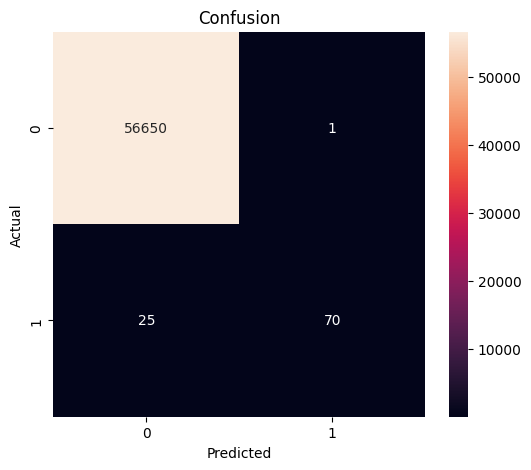

In [34]:
cm=confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion")
plt.show()

In [35]:
import optuna 
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score


c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [36]:
def objective(trial):
    params={
        "n_estimators":trial.suggest_int(
            "n_estimators",300,1000
        ),
        "max_depth":trial.suggest_int(
            "max_depth",3,10
        ),
        "learning_rate":trial.suggest_float(
            "learning_rate",0.01,0.15,log=True
        ),
        "subsample":trial.suggest_float(
            "subsample",0.6,1.0
        ),
        "colsample_bytree":trial.suggest_float(
            "colsample_bytree",0.6,1.0
        ),
        "min_child_weight":trial.suggest_int(
            "min_child_weight",1,10
        ),
        "gamma":trial.suggest_float(
            "gamma",0,5
        ),
        "reg_alpha":trial.suggest_float(
            "reg_alpha",1e-8,10,log=True
        ),
        "reg_lambda":trial.suggest_float(
            "reg_lambda",1e-8,10,log=True
        ),
        "scale_pos_weight":scale_pos_weight,
        "objective":"binary:logistic",
        "eval_metric":"aucpr",
        "random_state":42,
        "n_jobs":-1 
    }

    clf=XGBClassifier(**params)
    clf.fit(X_train,y_train,verbose=False)

    prob=clf.predict_proba(X_test)[:,1]
    return average_precision_score(y_test,prob)

In [37]:
study=optuna.create_study(direction="maximize")
study.optimize(
    objective,
    n_trials=10
)


[I 2026-10-06 06:57:11,348] A new study created in memory with name: no-name-bd3b3828-18ab-4a1a-87b3-a884739dbb0a


[I 2026-10-06 06:58:18,468] Trial 0 finished with value: 0.8091709658232632 and parameters: {'n_estimators': 983, 'max_depth': 7, 'learning_rate': 0.011959005397598749, 'subsample': 0.6139130906728657, 'colsample_bytree': 0.9948316000819002, 'min_child_weight': 8, 'gamma': 2.6761482964744934, 'reg_alpha': 2.4332471943783287e-06, 'reg_lambda': 8.6895175305497e-07}. Best is trial 0 with value: 0.8091709658232632.
[I 2026-10-06 06:58:45,494] Trial 1 finished with value: 0.8151265638940317 and parameters: {'n_estimators': 373, 'max_depth': 5, 'learning_rate': 0.04880674282219656, 'subsample': 0.681482672566481, 'colsample_bytree': 0.7639606277258595, 'min_child_weight': 9, 'gamma': 0.9019832013882567, 'reg_alpha': 2.9459352761906663, 'reg_lambda': 0.3308602107113048}. Best is trial 1 with value: 0.8151265638940317.
[I 2026-10-06 06:59:20,324] Trial 2 finished with value: 0.8176915119358714 and parameters: {'n_estimators': 749, 'max_depth': 6, 'learning_rate': 0.046554801966257074, 'subsamp

In [38]:
print("Best PR-AUC:",study.best_value)
print("n\ Best parameters:")

for key, value in study.best_params.items():
    print(key,":",value)

Best PR-AUC: 0.8260840143334438
n\ Best parameters:
n_estimators : 681
max_depth : 4
learning_rate : 0.07330954331819416
subsample : 0.8924716174056773
colsample_bytree : 0.9296725604240965
min_child_weight : 3
gamma : 2.4113552210540723
reg_alpha : 2.4995525816092496
reg_lambda : 2.7760579836012334e-06


In [39]:
best_params=study.best_params
final_model=XGBClassifier(
    **best_params,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)
final_model.fit(X_train,y_train,verbose=False)


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.9296725604240965
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'aucpr'


In [40]:
test_prob=final_model.predict_proba(X_test)[:,1]

In [41]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(
    0.05,
    0.96,
    0.01
)

results = []

for threshold in thresholds:

    pred = (test_prob >= threshold).astype(int)

    precision = precision_score(
        y_test,
        pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        pred,
        zero_division=0
    )

    results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

threshold_df = pd.DataFrame(results)

threshold_df.sort_values(
    "f1",
    ascending=False
).head(10)

,threshold,precision,recall,f1
45,0.50,0.972973,0.757895,0.852071
48,0.53,0.972973,0.757895,0.852071
47,0.52,0.972973,0.757895,0.852071
46,0.51,0.972973,0.757895,0.852071
40,0.45,0.960000,0.757895,0.847059
44,0.49,0.960000,0.757895,0.847059
43,0.48,0.960000,0.757895,0.847059
42,0.47,0.960000,0.757895,0.847059
41,0.46,0.960000,0.757895,0.847059
39,0.44,0.960000,0.757895,0.847059


In [43]:
best_threshold = threshold_df.loc[
    threshold_df["f1"].idxmax(),
    "threshold"
]

print("Best threshold:", best_threshold)

Best threshold: 0.5000000000000001


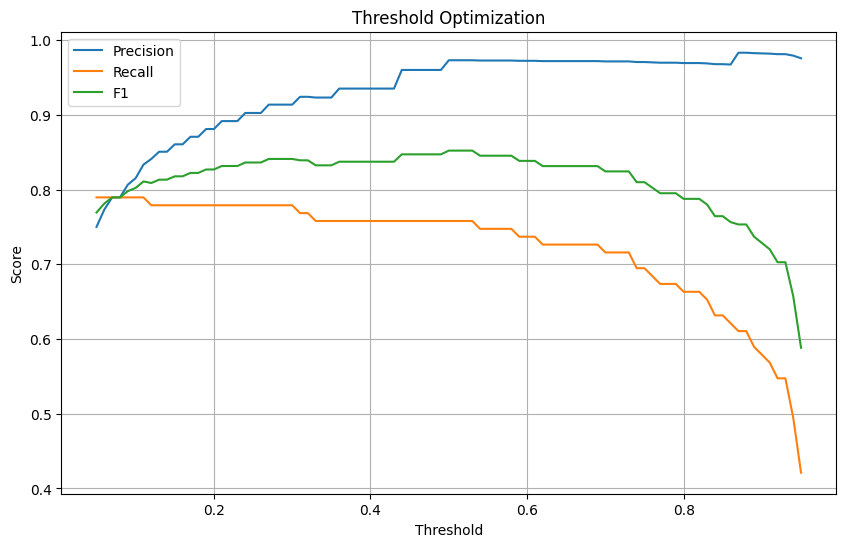

In [44]:
plt.figure(figsize=(10,6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    label="F1"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold Optimization")

plt.legend()
plt.grid()

plt.show()

In [45]:
final_pred = (
    test_prob >= best_threshold
).astype(int)

In [46]:
print(
    classification_report(
        y_test,
        final_pred,
        target_names=[
            "Genuine",
            "Fraud"
        ]
    )
)

              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00     56651
       Fraud       0.97      0.76      0.85        95

    accuracy                           1.00     56746
   macro avg       0.99      0.88      0.93     56746
weighted avg       1.00      1.00      1.00     56746



In [47]:
print(
    "ROC-AUC:",
    roc_auc_score(y_test, test_prob)
)

print(
    "PR-AUC:",
    average_precision_score(y_test, test_prob)
)

ROC-AUC: 0.9750021600399119
PR-AUC: 0.8055619833423943


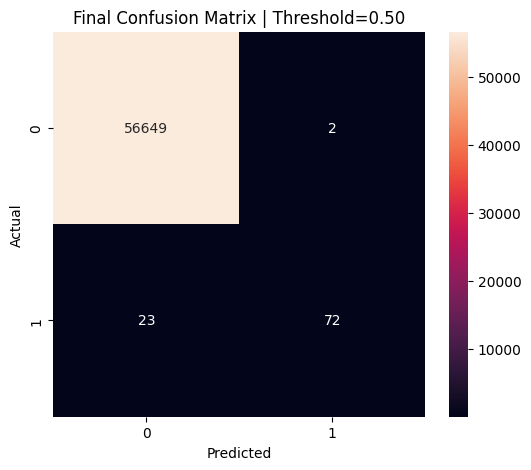

In [48]:
cm = confusion_matrix(
    y_test,
    final_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(
    f"Final Confusion Matrix | Threshold={best_threshold:.2f}"
)

plt.show()

In [49]:
importance = pd.Series(
    final_model.feature_importances_,
    index=X_train.columns
).sort_values(
    ascending=False
)

importance.head(20)

V14         0.267602
V10         0.175645
V17         0.073230
V12         0.064405
V7          0.041242
V4          0.028280
V16         0.020736
V25         0.019359
V26         0.018823
V2          0.018031
Hour_sin    0.016801
V24         0.015624
V5          0.015568
V23         0.014376
V21         0.014363
V20         0.014145
V27         0.014132
Amount      0.013301
V6          0.013090
V8          0.012959
dtype: float32

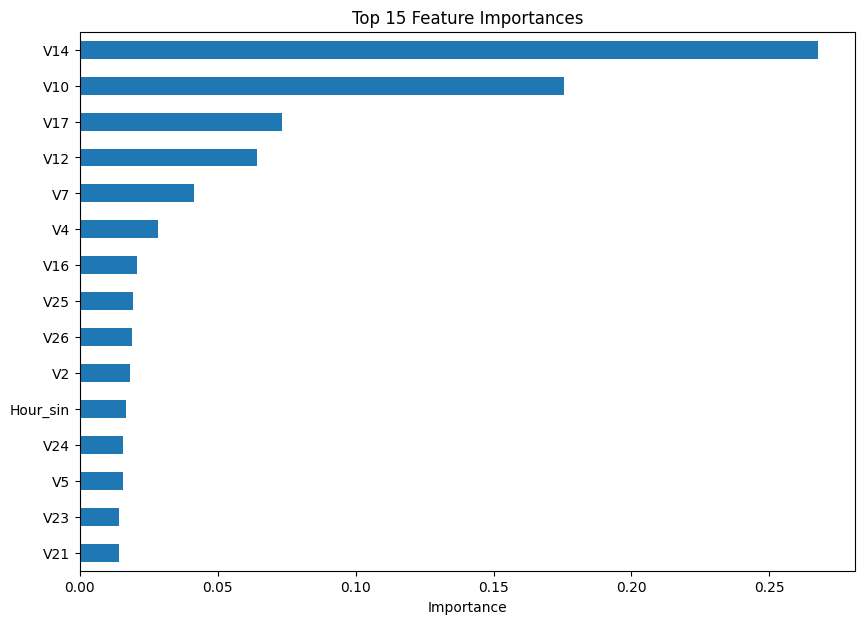

In [50]:
plt.figure(figsize=(10,7))

importance.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Feature Importances")
plt.xlabel("Importance")

plt.show()

In [51]:
# pip install shap

In [52]:
import shap

explainer = shap.TreeExplainer(final_model)

shap_values = explainer.shap_values(X_test)

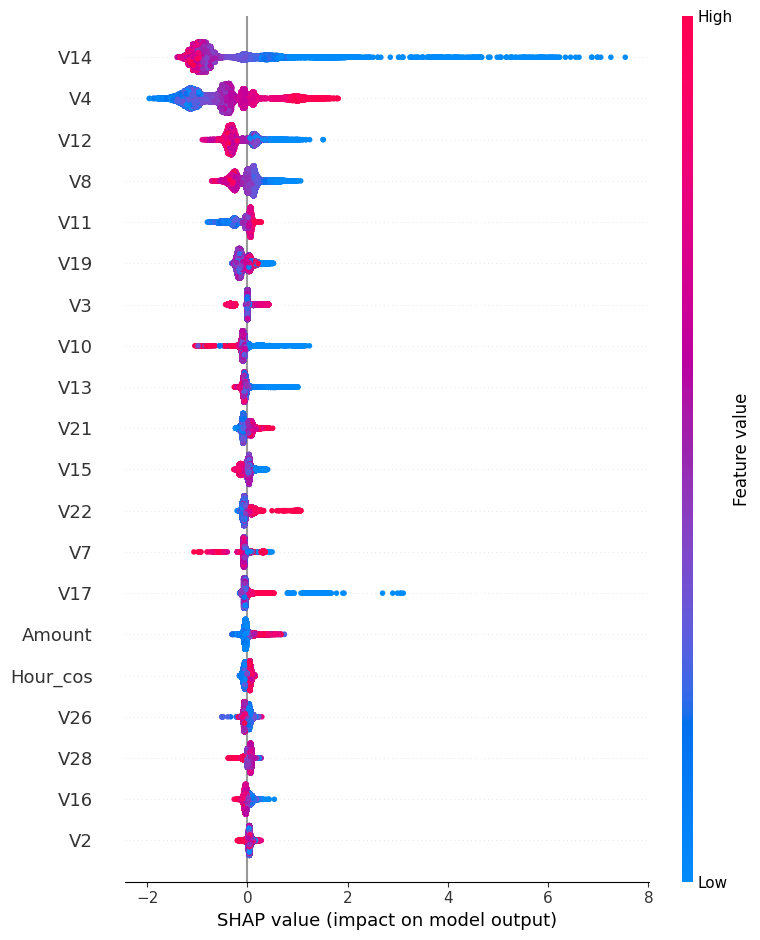

In [53]:
shap.summary_plot(
    shap_values,
    X_test
)

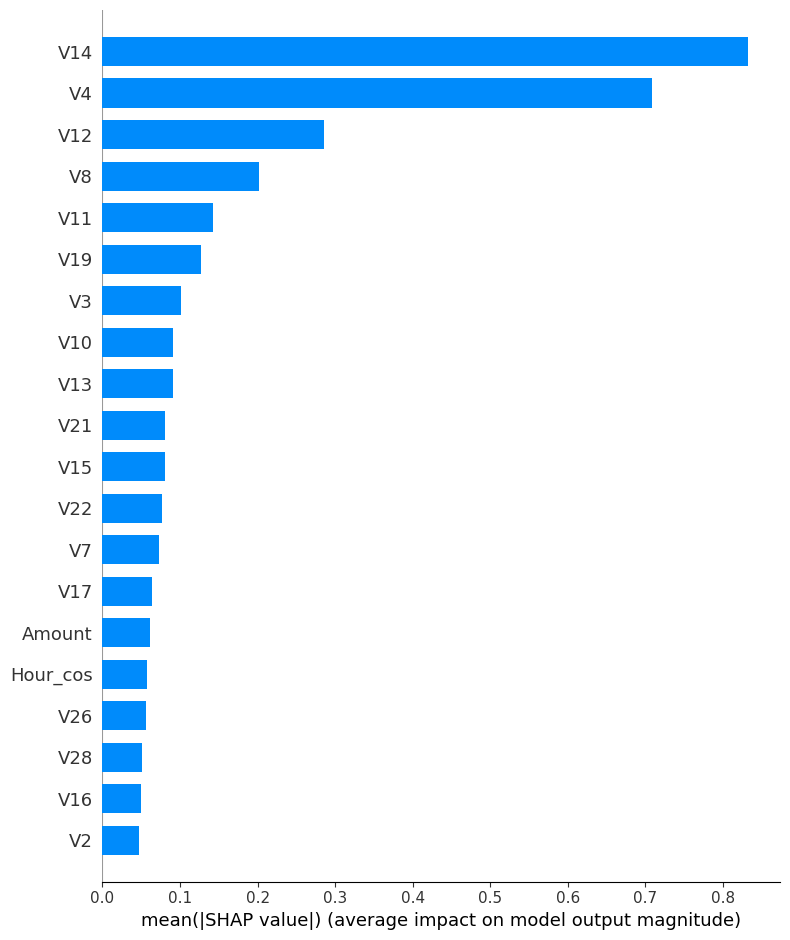

In [54]:
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar"
)

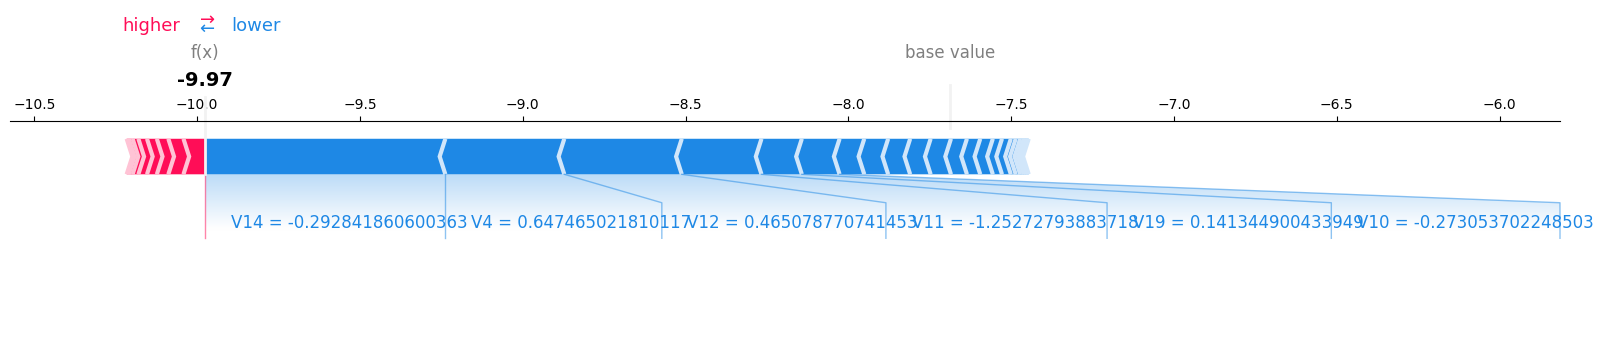

In [55]:
transaction_index = 0

shap.force_plot(
    explainer.expected_value,
    shap_values[transaction_index],
    X_test.iloc[transaction_index],
    matplotlib=True
)

In [56]:
import joblib

artifact = {
    "model": final_model,
    "threshold": float(best_threshold),
    "features": list(X_train.columns)
}

joblib.dump(
    artifact,
    "fraud_detection_model.pkl"
)

print("Model saved successfully.")

Model saved successfully.


In [ ]:
# docker build -t fraud-detection .

In [ ]:
# docker build -t fraud-detection .

In [ ]:
# docker compose up --build